# INF-42 · 출입 시각 오차 평가

2026년 10월 21~30일 출결 자료에서 실제 시각과 시스템 시각의 차이를 평가합니다.

## 결과 요약

- 실제·시스템 시각이 모두 있는 출입 기록 596건(IN 296, OUT 300)을 사용했습니다. 오차가 정확히 0분인 기록은 444건(74.5%)입니다.
- 전체 평균 절대오차는 11.159분 (95% 신뢰구간 [7.678, 16.757])이고, p95 절대오차는 63.000분 (95% 신뢰구간 [24.250, 87.750])입니다.
- 평균 오프셋은 입실 +10.162분, 퇴실 −5.825분입니다. 퇴실의 95% 신뢰구간에는 0이 포함됩니다.

## 자료와 방법

[Linear INF-42](https://linear.app/infer-ci-woosong/issue/INF-42/evaluate-attendance-timing-errors-with-infer-ci-ready-made-metrics)의 Resources에서 `attendance_times.csv`와 `attendance-data-guide.pdf`를 받습니다. 한 행은 한 사람의 하루입니다. 실제 출입 시각은 가이드에 따르면 사람이 확인한 기준값입니다.

- 입실(IN)과 퇴실(OUT)마다 실제·시스템 시각이 모두 있는 쌍을 사용합니다.
- 전체 날짜와 시간을 2026-10-21 00:00부터 지난 분으로 변환합니다. 퇴실 시각이 다음 날이면 입력의 날짜를 그대로 사용합니다.
- 평균 오프셋은 `시스템 − 실제`입니다. 양수는 늦게, 음수는 일찍 기록됐음을 뜻합니다. MAE, 중앙값, RMSE, p95는 오차의 크기를 봅니다.
- 95% 신뢰구간은 infer-ci로 계산합니다. 중앙값에는 이슈에 지정된 백분위 부트스트랩을 쓰고, 나머지는 BCa를 씁니다. 각 계산에 재표집 9,999회와 `random_state=0`을 사용합니다.

### 실행 준비

검증에 사용한 원본 [infer-ci `dev` 소스 `cbfa221`](https://github.com/humblebeeai/infer-ci/tree/cbfa221e0c0cc89f137e8cda18f6cb7964c2838f)와 Python 3.11.9 환경을 준비합니다. 저장소 루트에서 다음 명령을 실행해 패키지를 설치하고, 같은 Python 환경을 Jupyter 커널로 선택합니다.

```bash
python -m pip install -e . ipykernel "numpy==2.4.6" "scipy==1.17.1" "pandas==3.1.1" "matplotlib==3.11.2"
```

Linear Resources에서 받은 CSV를 노트북 폴더에 두거나 Jupyter 실행 전에 `ATTENDANCE_CSV` 환경 변수에 파일의 절대 경로를 지정합니다. 실행 결과에는 집계표와 그래프를 저장합니다.

In [1]:
from hashlib import sha256
import os
from pathlib import Path
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
from IPython.display import display
from infer_ci import __version__ as infer_version
from infer_ci import bootstrap_ci, mae, mean_bia_dev, med_abs_err, rmse

csv_path = Path(os.environ.get("ATTENDANCE_CSV", "attendance_times.csv"))
if not csv_path.is_file():
    raise FileNotFoundError("Linear INF-42에서 attendance_times.csv를 받아 ATTENDANCE_CSV에 경로를 지정하세요.")

print(f"Python {platform.python_version()} | infer-ci {infer_version}")
print(f"pandas {pd.__version__} | NumPy {np.__version__} | SciPy {scipy.__version__} | Matplotlib {matplotlib.__version__}")
print(f"CSV SHA-256: {sha256(csv_path.read_bytes()).hexdigest()}")

Python 3.11.9 | infer-ci 0.2.1
pandas 3.1.1 | NumPy 2.4.6 | SciPy 1.17.1 | Matplotlib 3.11.2
CSV SHA-256: 695cfac117ff7ab124e65d295a0b5dcef22469d4d264903fea6f0984b06ea7be


## 입력 읽기와 분석 대상 확인

빈 칸은 해당 시각의 결측으로 처리합니다. 각 방향에서 실제와 시스템 기록이 모두 있는 경우를 모으고, 한쪽 또는 양쪽 시각이 없는 행의 수는 별도로 확인합니다.

In [2]:
time_columns = ["real_in", "system_in", "real_out", "system_out"]
daily = pd.read_csv(csv_path, usecols=["person_id", *time_columns], dtype="string")
for column in time_columns:
    daily[column] = pd.to_datetime(daily[column], format="%Y-%m-%d %H:%M:%S", errors="raise")

paired_inputs = pd.concat(
    [
        daily[["real_in", "system_in"]].set_axis(["real", "system"], axis=1).assign(direction="IN"),
        daily[["real_out", "system_out"]].set_axis(["real", "system"], axis=1).assign(direction="OUT"),
    ],
    ignore_index=True,
)

has_real = paired_inputs["real"].notna()
has_system = paired_inputs["system"].notna()
eligibility = (
    paired_inputs.assign(
        paired=has_real & has_system,
        missed=has_real & ~has_system,
        extra=~has_real & has_system,
        both_missing=~has_real & ~has_system,
    )
    .groupby("direction")[["paired", "missed", "extra", "both_missing"]]
    .sum()
)
paired = paired_inputs.loc[has_real & has_system].copy()
origin = pd.Timestamp("2026-10-21 00:00:00")
for column in ["real", "system"]:
    paired[f"{column}_min"] = (paired[column] - origin).dt.total_seconds() / 60

# 원본 날짜·시간끼리 직접 뺀 값으로 분 변환의 방향과 크기를 검증합니다.
paired["error_min"] = (paired["system"] - paired["real"]).dt.total_seconds() / 60
np.testing.assert_allclose(paired.system_min - paired.real_min, paired.error_min, atol=1e-9, rtol=0)
expected_pairs = {"IN": 296, "OUT": 300}
observed_pairs = eligibility["paired"].to_dict()
if len(daily) != 315 or observed_pairs != expected_pairs:
    raise ValueError(f"INF-42 예상 행 수와 다릅니다. 원본 {len(daily)}행, 시각 쌍 {observed_pairs}")
assert len(paired) == sum(expected_pairs.values())
assert int(eligibility.to_numpy().sum()) == 2 * len(daily)
display(eligibility)
print(f"오차가 정확히 0분인 기록: {(paired.error_min == 0).sum()}/{len(paired)}")

,paired,missed,extra,both_missing
direction,,,,
IN,296,4,7,8
OUT,300,0,6,9


오차가 정확히 0분인 기록: 444/596


## 결과

값과 95% 신뢰구간 하한·상한의 단위는 모두 분입니다. p95는 관측된 절대오차의 95번째 백분위수이고, p95 행의 하한과 상한은 그 백분위수 추정치의 95% 신뢰구간입니다.

In [3]:
def p95_absolute_error(real, system):
    return np.percentile(np.abs(system - real), 95)

metrics = {
    "MAE": (mae, "bootstrap_bca", {}),
    "Mean offset": (mean_bia_dev, "bootstrap_bca", {}),
    "Median absolute error": (med_abs_err, "bootstrap_percentile", {}),
    "RMSE": (rmse, "bootstrap_bca", {}),
    "p95 absolute error": (bootstrap_ci, "bootstrap_bca", {"metric": p95_absolute_error}),
}

groups = {
    "All": paired,
    "IN": paired.loc[paired.direction.eq("IN")],
    "OUT": paired.loc[paired.direction.eq("OUT")],
}
results = []
for group, rows in groups.items():
    real = rows.real_min.to_numpy()
    system = rows.system_min.to_numpy()
    absolute_error = rows.error_min.abs()
    expected = [
        absolute_error.mean(),
        rows.error_min.mean(),
        absolute_error.median(),
        np.sqrt((rows.error_min ** 2).mean()),
        absolute_error.quantile(0.95),
    ]
    for (label, (function, method, options)), reference in zip(metrics.items(), expected, strict=True):
        value, (lower, upper) = function(
            real, system, confidence_level=0.95, method=method,
            n_resamples=9999, random_state=0, show_progress=False, **options,
        )
        np.testing.assert_allclose(value, reference, atol=1e-9, rtol=0)
        if not np.isfinite([value, lower, upper]).all() or lower > upper:
            raise ValueError(f"{group} / {label}: 유효하지 않은 신뢰구간")
        results.append((group, label, len(rows), value, lower, upper))

results_table = pd.DataFrame(results, columns=["Group", "Metric", "N", "Value", "Lower", "Upper"])
display(results_table.style.format({"Value": "{:.3f}", "Lower": "{:.3f}", "Upper": "{:.3f}"}).hide(axis="index"))
print("검증: 전체·입실·퇴실의 점추정값 15개를 타임스탬프 차이에서 직접 계산한 값과 대조했습니다.")

Group,Metric,N,Value,Lower,Upper
All,MAE,596,11.159,7.678,16.757
All,Mean offset,596,2.115,-1.816,7.298
All,Median absolute error,596,0.000,0.000,0.000
All,RMSE,596,55.794,39.935,81.550
All,p95 absolute error,596,63.000,24.250,87.750
IN,MAE,296,10.385,6.155,18.079
IN,Mean offset,296,10.162,5.929,17.954
IN,Median absolute error,296,0.000,0.000,0.000
IN,RMSE,296,50.756,32.816,81.439
IN,p95 absolute error,296,59.250,16.250,96.000


검증: 전체·입실·퇴실의 점추정값 15개를 타임스탬프 차이에서 직접 계산한 값과 대조했습니다.


### 평균 오프셋과 꼬리 오차

점은 추정값, 가로선은 95% 신뢰구간입니다. 왼쪽은 시스템 기록이 빠른지 늦은지, 오른쪽은 오차가 큰 구간에서 차이가 어느 정도인지 보여 줍니다.

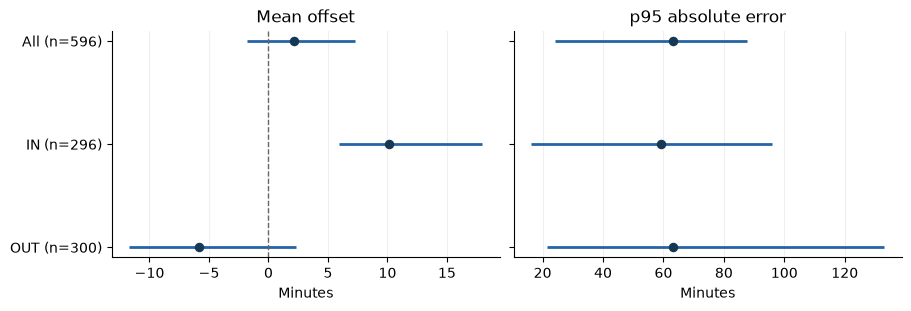

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.0), sharey=True, layout="constrained")
for ax, metric in zip(axes, ["Mean offset", "p95 absolute error"], strict=True):
    subset = results_table.loc[results_table.Metric.eq(metric)]
    ypos = np.arange(len(subset))
    ax.hlines(ypos, subset.Lower, subset.Upper, color="#2563a6", linewidth=2)
    ax.scatter(subset.Value, ypos, color="#153855", s=34, zorder=3)
    ax.set_title(metric)
    ax.set_xlabel("Minutes")
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].axvline(0, color="#666666", linestyle="--", linewidth=1)
axes[0].set_yticks(ypos, [f"{group} (n={len(rows)})" for group, rows in groups.items()])
axes[0].invert_yaxis()
plt.show()

## 해석과 한계

- 시간 지표의 범위는 실제 시각과 시스템 시각이 모두 있는 출입 기록입니다. 누락과 추가 기록의 빈도는 별도의 출결 정확도 과제에서 다룹니다.
- 세 그룹 모두 절대오차 중앙값이 0분이고, 행 단위 백분위 부트스트랩에서 중앙값의 95% 신뢰구간은 [0, 0]분입니다. 전체 MAE 11.159분과 p95 63분은 오차가 남아 있는 기록의 영향도 함께 보여 줍니다.
- 같은 사람이 여러 날 반복 등장하고 한 사람의 입실·퇴실 기록이 연관될 수 있습니다. 기록 행을 재표집한 신뢰구간은 이 의존성을 반영하지 않아 실제보다 좁을 수 있습니다.
- 전체 평균 오프셋의 구간은 [-1.816, 7.298]분입니다. 평균이 +2.115분이지만 이 데이터로 전체 기록이 한 방향으로 치우쳤다고 단정하기 어렵습니다.